<a href="https://colab.research.google.com/github/NINE4zzzz/Auto-mpg-dataset/blob/main/zadorin_AI_impact_on_students.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Полиномиальная регрессия: прогнозирование расхода топлива (MPG)

**Датасет:** [Auto MPG Dataset (Kaggle, uciml/autompg-dataset)](https://www.kaggle.com/datasets/uciml/autompg-dataset) — 398 автомобилей 1970–1982 годов выпуска, целевая переменная `mpg` (миль на галлон).

**План работы:**
1. Загрузка и первичный анализ данных
2. Подготовка данных и базовая (линейная) модель
3. Полиномиальные признаки: подбор оптимальной степени
4. Регуляризация: Ridge и Lasso
5. Итоговое сравнение моделей и выводы


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, validation_curve, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 1. Загрузка и первичный анализ данных

In [2]:
DATA_PATH = "auto-mpg.csv"

if not os.path.exists(DATA_PATH):
    # Опциональная автоматическая загрузка с Kaggle (требуется настроенный Kaggle API).
    try:
        import kagglehub
        kaggle_dir = kagglehub.dataset_download("uciml/autompg-dataset")
        DATA_PATH = os.path.join(kaggle_dir, "auto-mpg.csv")
    except Exception as exc:
        raise FileNotFoundError(
            "Файл auto-mpg.csv не найден рядом с ноутбуком, а автоматическая "
            "загрузка с Kaggle не удалась. Скачайте датасет с "
            "https://www.kaggle.com/datasets/uciml/autompg-dataset и "
            "положите auto-mpg.csv рядом с этим ноутбуком."
        ) from exc

df_raw = pd.read_csv(DATA_PATH)
print(f"Размер датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов")
df_raw.head()

Размер датасета: 398 строк, 9 столбцов


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


Столбец `horsepower` при чтении CSV имеет тип `float64` уже с пропусками
(в исходном файле у 6 автомобилей мощность не указана). Проверим пропуски по всем столбцам:

In [4]:
missing = df_raw.isna().sum()
missing = missing[missing > 0]
print("Пропуски по столбцам:")
print(missing if len(missing) else "пропусков нет")

Пропуски по столбцам:
horsepower    6
dtype: int64


In [5]:
df_raw.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [6]:
print("Уникальные значения origin:", sorted(df_raw['origin'].unique()))
print("Уникальные значения cylinders:", sorted(df_raw['cylinders'].unique()))
print("Диапазон model_year:", df_raw['model_year'].min(), "-", df_raw['model_year'].max())
print("Количество уникальных моделей (name):", df_raw['name'].nunique())

Уникальные значения origin: ['europe', 'japan', 'usa']
Уникальные значения cylinders: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(8)]
Диапазон model_year: 70 - 82
Количество уникальных моделей (name): 305


**Выводы по первичному анализу:**
- В датасете 398 наблюдений, 9 столбцов, целевая переменная — `mpg`.
- Пропуски есть только в `horsepower` (6 значений из 398, около 1.5%) — это ожидаемо для данного датасета и упомянуто в его описании.
- `cylinders` (3,4,5,6,8), `model_year` (70–82) и `origin` (usa/europe/japan) — категориальные/дискретные признаки, `name` — уникальный текстовый идентификатор, для регрессии бесполезен.
- Признаки `displacement`, `horsepower`, `weight`, `acceleration` — непрерывные, именно на них будем строить полиномиальные признаки.

### Предобработка перед разведочным анализом

In [7]:
df = df_raw.copy()

# Пропуски в horsepower заполняем медианой (устойчива к выбросам)
median_hp = df['horsepower'].median()
df['horsepower'] = df['horsepower'].fillna(median_hp)
print(f"Пропуски в horsepower заполнены медианой = {median_hp}")

# car name не несёт предсказательной силы для регрессии
df = df.drop(columns=['name'])

# Категориальные признаки переводим в тип category
for col in ['cylinders', 'model_year', 'origin']:
    df[col] = df[col].astype('category')

print("\nПропусков в датафрейме:", df.isna().sum().sum())
df.dtypes

Пропуски в horsepower заполнены медианой = 93.5

Пропусков в датафрейме: 0


,0
mpg,float64
cylinders,category
displacement,float64
horsepower,float64
weight,int64
acceleration,float64
model_year,category
origin,category


### Корреляционная матрица

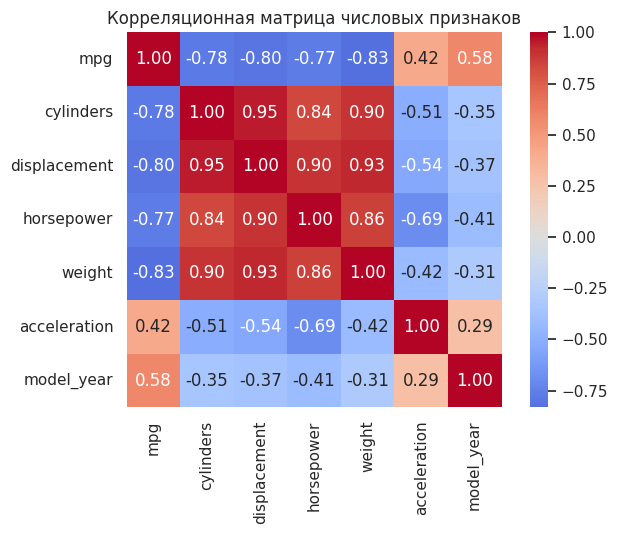

Корреляция признаков с mpg (по убыванию силы связи):
weight         -0.831741
displacement   -0.804203
cylinders      -0.775396
horsepower     -0.773453
model_year      0.579267
acceleration    0.420289
Name: mpg, dtype: float64


In [8]:
# origin — номинальный (не упорядоченный) признак, корреляцию для него не считаем.
# cylinders и model_year остаются содержательно упорядоченными числовыми величинами.
corr_df = df.copy()
corr_df['cylinders'] = corr_df['cylinders'].astype(int)
corr_df['model_year'] = corr_df['model_year'].astype(int)
corr_matrix = corr_df.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

print("Корреляция признаков с mpg (по убыванию силы связи):")
print(corr_matrix['mpg'].drop('mpg').sort_values(key=abs, ascending=False))

**Наблюдения:** `weight`, `displacement`, `cylinders` и `horsepower` сильно **отрицательно**
коррелируют с `mpg` (|r| в районе 0.77–0.83) — чем тяжелее машина и мощнее/крупнее двигатель, тем выше расход топлива.
`model_year` умеренно **положительно** коррелирует с `mpg` (r ≈ 0.58) — более новые машины экономичнее.
`acceleration` слабо положительно связана с `mpg` (r ≈ 0.42). Сами признаки `weight`/`displacement`/`horsepower`/`cylinders`
между собой тоже сильно коррелированы (мультиколлинеарность) — это стоит учитывать при интерпретации коэффициентов линейной модели.

### Парные диаграммы рассеяния (pairplot)

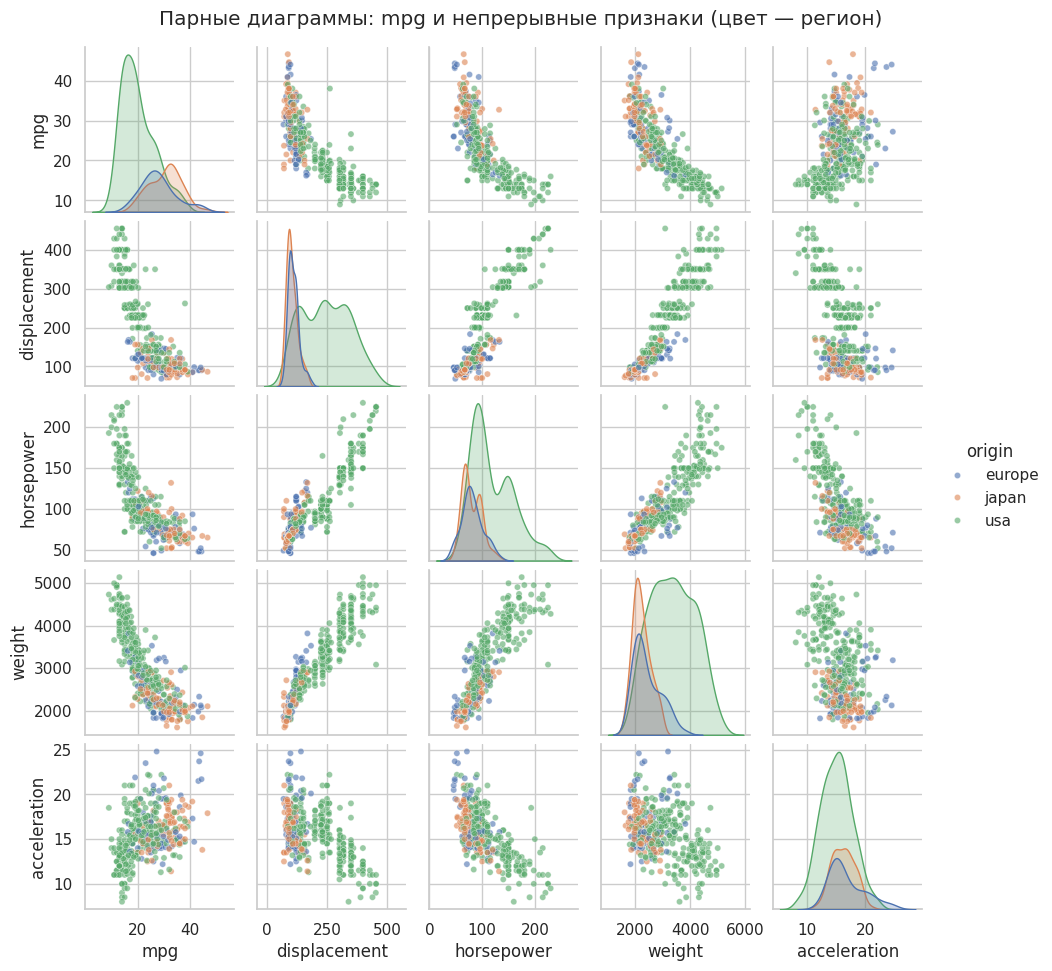

In [9]:
continuous_features = ['displacement', 'horsepower', 'weight', 'acceleration']

pair_grid = sns.pairplot(
    df[['mpg'] + continuous_features + ['origin']],
    hue='origin', diag_kind='kde', height=1.9, plot_kws={'alpha': 0.6, 's': 20}
)
pair_grid.fig.suptitle("Парные диаграммы: mpg и непрерывные признаки (цвет — регион)", y=1.02)
plt.show()

На диаграммах видна выраженная **нелинейность** связи `mpg` с `weight`, `displacement` и `horsepower` —
точки ложатся не на прямую, а на затухающую кривую (убывание mpg замедляется при больших значениях признака).
Это прямое обоснование того, зачем нужны полиномиальные признаки: линейная модель такую форму связи
описать не может, а модель со степенью 2 — может. Также заметно, что автомобили из Японии (japan) и Европы (europe)
в среднем легче и экономичнее машин из США (usa).

## 2. Подготовка данных и базовая линейная модель

Категориальные признаки (`cylinders`, `model_year`, `origin`) кодируем через **one-hot encoding**
(`pd.get_dummies`, с `drop_first=True` во избежание мультиколлинеарности от фиктивной переменной-ловушки).
Непрерывные признаки (`displacement`, `horsepower`, `weight`, `acceleration`) оставляем как есть — они будут
масштабированы и полиномиально расширены на следующем шаге.

In [10]:
categorical_features = ['cylinders', 'model_year', 'origin']

df_enc = pd.get_dummies(df, columns=categorical_features, drop_first=True)
print(f"После one-hot encoding: {df_enc.shape[1] - 1} признаков (без учёта mpg)")

X = df_enc.drop(columns=['mpg'])
y = df_enc['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} строк, Test: {X_test.shape[0]} строк")

После one-hot encoding: 22 признаков (без учёта mpg)
Train: 278 строк, Test: 120 строк


### Базовая модель: линейная регрессия на исходных (неполиномиальных) признаках

In [11]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

pred_train = baseline_model.predict(X_train)
pred_test = baseline_model.predict(X_test)

def print_metrics(name, y_tr, pred_tr, y_te, pred_te):
    print(f"--- {name} ---")
    print(f"Train:  MSE = {mean_squared_error(y_tr, pred_tr):.3f}   R2 = {r2_score(y_tr, pred_tr):.3f}")
    print(f"Test:   MSE = {mean_squared_error(y_te, pred_te):.3f}   R2 = {r2_score(y_te, pred_te):.3f}")

print_metrics("Линейная регрессия (baseline)", y_train, pred_train, y_test, pred_test)

--- Линейная регрессия (baseline) ---
Train:  MSE = 8.006   R2 = 0.872
Test:   MSE = 7.876   R2 = 0.863


**Краевой случай / потенциальная проблема:** признаки находятся в очень разных масштабах
(`weight` ~ тысячи, `acceleration` ~ десятки) — для обычной `LinearRegression` без регуляризации это не влияет
на итоговые предсказания и R²/MSE (модель инвариантна к линейному масштабированию признаков), но становится
критичным для Ridge/Lasso и для полиномиальных признаков — там масштабирование обязательно, иначе штраф
регуляризации будет несправедливо сильнее давить на признаки с большим числовым диапазоном.

## 3. Полиномиальные признаки: подбор оптимальной степени

Строим пайплайн **Масштабирование → PolynomialFeatures → Линейная регрессия**.
Через `ColumnTransformer` полиномиальному расширению и масштабированию подвергаются **только непрерывные
признаки** (`displacement`, `horsepower`, `weight`, `acceleration`); категориальные dummy-столбцы (0/1)
передаются в модель без изменений — их возведение в степень не имеет смысла.

In [12]:
def build_pipeline(model, degree):
    preprocessor = ColumnTransformer(
        transformers=[
            ('poly', Pipeline([
                ('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
            ]), continuous_features)
        ],
        remainder='passthrough'  # категориальные dummy-признаки проходят без изменений
    )
    return Pipeline([('preprocessor', preprocessor), ('model', model)])

# Проверка на степени 2
example_pipe = build_pipeline(LinearRegression(), degree=2)
example_pipe.fit(X_train, y_train)
n_features_out = example_pipe.named_steps['preprocessor'].transform(X_train).shape[1]
print(f"Пример: при degree=2 итоговое число признаков на входе модели = {n_features_out}")

Пример: при degree=2 итоговое число признаков на входе модели = 32


### Подбор степени полинома по кросс-валидации (validation curve)

In [13]:
degrees = range(1, 11)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_for_degree_search = build_pipeline(LinearRegression(), degree=1)

train_scores, val_scores = validation_curve(
    pipe_for_degree_search, X_train, y_train,
    param_name='preprocessor__poly__poly__degree', param_range=degrees,
    cv=cv, scoring='neg_mean_squared_error', n_jobs=-1
)

train_mse_by_degree = -train_scores.mean(axis=1)
val_mse_by_degree = -val_scores.mean(axis=1)

results_degree = pd.DataFrame({
    'degree': list(degrees),
    'train_MSE': train_mse_by_degree,
    'cv_MSE': val_mse_by_degree,
})
print(results_degree.to_string(index=False))

best_degree = int(results_degree.loc[results_degree['cv_MSE'].idxmin(), 'degree'])
print(f"\nОптимальная степень полинома (минимум CV MSE): {best_degree}")

 degree    train_MSE       cv_MSE
      1 7.778012e+00 1.061500e+01
      2 6.056839e+00 1.028354e+01
      3 5.063278e+00 4.416378e+01
      4 3.814557e+00 4.184696e+03
      5 2.112147e+00 2.186514e+06
      6 3.489048e-17 2.008888e+10
      7 7.832450e-20 2.777899e+08
      8 2.804530e-20 1.598240e+07
      9 1.314580e-19 8.023903e+07
     10 2.048851e-18 6.190299e+08

Оптимальная степень полинома (минимум CV MSE): 2


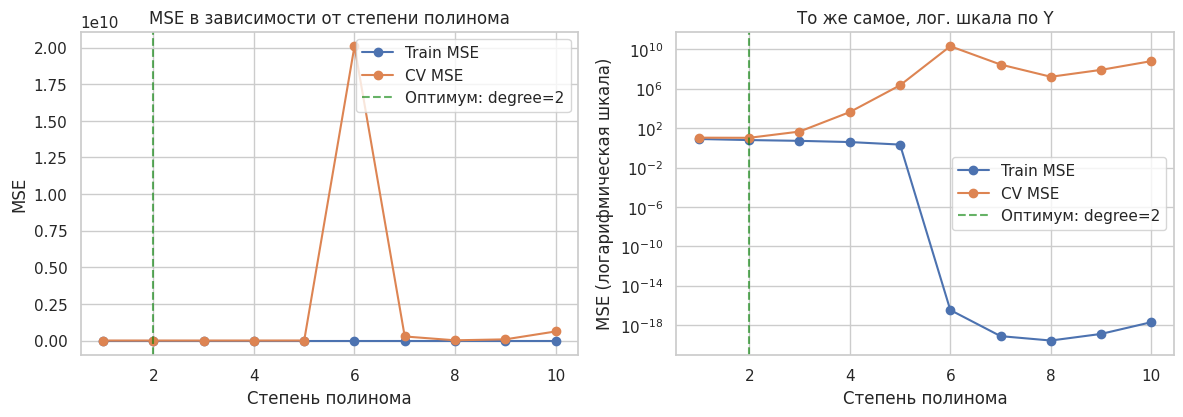

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(degrees, train_mse_by_degree, marker='o', label='Train MSE')
axes[0].plot(degrees, val_mse_by_degree, marker='o', label='CV MSE')
axes[0].axvline(best_degree, color='green', linestyle='--', alpha=0.6, label=f'Оптимум: degree={best_degree}')
axes[0].set_xlabel('Степень полинома')
axes[0].set_ylabel('MSE')
axes[0].set_title('MSE в зависимости от степени полинома')
axes[0].legend()

axes[1].plot(degrees, train_mse_by_degree, marker='o', label='Train MSE')
axes[1].plot(degrees, val_mse_by_degree, marker='o', label='CV MSE')
axes[1].axvline(best_degree, color='green', linestyle='--', alpha=0.6, label=f'Оптимум: degree={best_degree}')
axes[1].set_yscale('log')
axes[1].set_xlabel('Степень полинома')
axes[1].set_ylabel('MSE (логарифмическая шкала)')
axes[1].set_title('То же самое, лог. шкала по Y')
axes[1].legend()

plt.tight_layout()
plt.show()

**Интерпретация:** train MSE монотонно убывает с ростом степени (модель всё точнее подгоняется
под обучающую выборку, вплоть до идеальной подгонки при degree ≥ 6). CV MSE, напротив, минимальна при
degree = 2, а начиная с degree = 3–4 резко **взрывается** — это классическая картина **переобучения**:
на небольшом наборе данных (278 строк в train) полиномы высоких степеней от четырёх признаков порождают
огромное количество сильно коррелированных признаков и создают числовую неустойчивость (мультиколлинеарность),
из-за которой модель на новых данных предсказывает случайные величины. Оптимальная степень — **2**: она
достаточно гибкая, чтобы уловить нелинейность (см. pairplot), но не переобучается.

## 4. Регуляризация: Ridge и Lasso

Фиксируем `degree=2` (найденную выше оптимальную степень) и подбираем коэффициент
регуляризации `alpha` для Ridge и Lasso по той же схеме — validation curve с 5-fold кросс-валидацией.

In [15]:
alphas = np.logspace(-3, 2, 20)

alpha_results = {}
for name, ModelClass, extra_kwargs in [
    ('Ridge', Ridge, {}),
    ('Lasso', Lasso, {'max_iter': 20000}),
]:
    pipe = build_pipeline(ModelClass(**extra_kwargs), degree=best_degree)
    train_sc, val_sc = validation_curve(
        pipe, X_train, y_train,
        param_name='model__alpha', param_range=alphas,
        cv=cv, scoring='neg_mean_squared_error', n_jobs=-1
    )
    alpha_results[name] = {
        'train_mse': -train_sc.mean(axis=1),
        'val_mse': -val_sc.mean(axis=1),
    }

best_alphas = {}
for name in ['Ridge', 'Lasso']:
    idx_best = int(np.argmin(alpha_results[name]['val_mse']))
    best_alphas[name] = alphas[idx_best]
    print(f"{name}: лучший alpha = {alphas[idx_best]:.4f}, "
          f"CV MSE = {alpha_results[name]['val_mse'][idx_best]:.3f}")

Ridge: лучший alpha = 2.6367, CV MSE = 9.831
Lasso: лучший alpha = 0.0379, CV MSE = 9.288


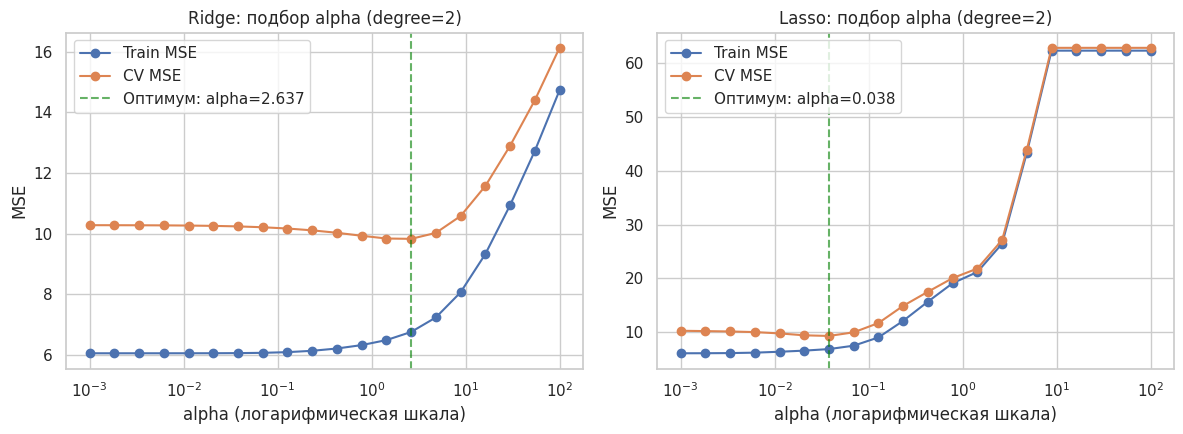

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, name in zip(axes, ['Ridge', 'Lasso']):
    ax.semilogx(alphas, alpha_results[name]['train_mse'], marker='o', label='Train MSE')
    ax.semilogx(alphas, alpha_results[name]['val_mse'], marker='o', label='CV MSE')
    ax.axvline(best_alphas[name], color='green', linestyle='--', alpha=0.6,
               label=f"Оптимум: alpha={best_alphas[name]:.3f}")
    ax.set_xlabel('alpha (логарифмическая шкала)')
    ax.set_ylabel('MSE')
    ax.set_title(f'{name}: подбор alpha (degree={best_degree})')
    ax.legend()

plt.tight_layout()
plt.show()

**Наблюдение:** у Ridge оптимум CV MSE — широкий пологий минимум в районе alpha ≈ 1–3:
при очень маленьких alpha регуляризация почти не действует (MSE близка к обычной полиномиальной регрессии),
при очень больших — модель чрезмерно "сжимает" коэффициенты и недообучается. У Lasso минимум более острый
и находится при заметно меньшем alpha (~0.03–0.04): Lasso обнуляет коэффициенты быстрее (L1-штраф), поэтому
уже при относительно небольшом alpha начинает терять полезные признаки, и MSE растёт.

### Коэффициенты Lasso: какие признаки модель посчитала важными

In [17]:
best_alpha_lasso = best_alphas['Lasso']
lasso_pipe = build_pipeline(Lasso(alpha=best_alpha_lasso, max_iter=20000), degree=best_degree)
lasso_pipe.fit(X_train, y_train)

feature_names = lasso_pipe.named_steps['preprocessor'].get_feature_names_out()
coefs = lasso_pipe.named_steps['model'].coef_

coef_table = (
    pd.DataFrame({'feature': feature_names, 'coef': coefs})
    .assign(abs_coef=lambda d: d['coef'].abs())
    .sort_values('abs_coef', ascending=False)
)

n_nonzero = int((coefs != 0).sum())
n_zero = int((coefs == 0).sum())
print(f"Lasso (alpha={best_alpha_lasso:.4f}) оставил {n_nonzero} признаков из {len(coefs)} "
      f"(обнулил {n_zero}) — автоматический отбор признаков.\n")
print("Топ-12 признаков по модулю коэффициента:")
print(coef_table.head(12)[['feature', 'coef']].to_string(index=False))

Lasso (alpha=0.0379) оставил 24 признаков из 32 (обнулил 8) — автоматический отбор признаков.

Топ-12 признаков по модулю коэффициента:
                 feature      coef
remainder__model_year_80  7.371331
remainder__model_year_82  6.510222
remainder__model_year_81  4.488784
            poly__weight -3.965437
remainder__model_year_79  3.142502
remainder__model_year_73 -2.251199
        poly__horsepower -2.122417
remainder__model_year_78  1.508314
remainder__model_year_72 -1.447045
   remainder__origin_usa -1.296340
          poly__weight^2  0.992423
  remainder__cylinders_4  0.496287


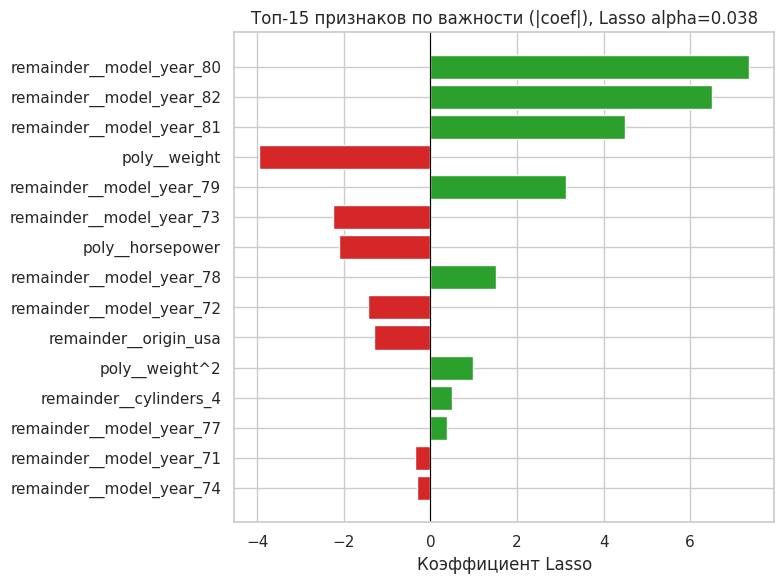

In [18]:
top_features = coef_table.head(15)
plt.figure(figsize=(8, 6))
colors = ['#d62728' if c < 0 else '#2ca02c' for c in top_features['coef']]
plt.barh(top_features['feature'][::-1], top_features['coef'][::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коэффициент Lasso')
plt.title(f'Топ-15 признаков по важности (|coef|), Lasso alpha={best_alpha_lasso:.3f}')
plt.tight_layout()
plt.show()

**Интерпретация:** сильнее всего на `mpg` влияют `model_year` (более новые годы — сильно
положительный вклад, машины 1980–82 годов заметно экономичнее базового 1970 года), `weight` (отрицательный —
чем тяжелее, тем меньше mpg) и `horsepower` (тоже отрицательный). Lasso обнулил около четверти признаков
(в основном взаимодействия/квадраты, слабо связанные с целевой переменной, и часть индикаторов `model_year`
с близкими к нулю эффектами) — это подтверждает, что не все полиномиальные признаки полезны, и Lasso
действительно выполняет отбор признаков, а не просто "сжимает" все коэффициенты одинаково, как Ridge.

## 5. Итоговое сравнение моделей

In [19]:
best_alpha_ridge = best_alphas['Ridge']

final_models = {
    'Linear (baseline, без полиномов)': LinearRegression(),
}

final_pipelines = {
    f'Polynomial deg={best_degree} (без регуляризации)': build_pipeline(LinearRegression(), degree=best_degree),
    f'Ridge (deg={best_degree}, alpha={best_alpha_ridge:.3f})': build_pipeline(Ridge(alpha=best_alpha_ridge), degree=best_degree),
    f'Lasso (deg={best_degree}, alpha={best_alpha_lasso:.3f})': build_pipeline(Lasso(alpha=best_alpha_lasso, max_iter=20000), degree=best_degree),
}

rows = []

# baseline (без пайплайна с полиномами)
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pr_tr, pr_te = model.predict(X_train), model.predict(X_test)
    rows.append({
        'model': name,
        'train_MSE': mean_squared_error(y_train, pr_tr), 'train_R2': r2_score(y_train, pr_tr),
        'test_MSE': mean_squared_error(y_test, pr_te), 'test_R2': r2_score(y_test, pr_te),
    })

test_predictions = {}
for name, pipe in final_pipelines.items():
    pipe.fit(X_train, y_train)
    pr_tr, pr_te = pipe.predict(X_train), pipe.predict(X_test)
    test_predictions[name] = pr_te
    rows.append({
        'model': name,
        'train_MSE': mean_squared_error(y_train, pr_tr), 'train_R2': r2_score(y_train, pr_tr),
        'test_MSE': mean_squared_error(y_test, pr_te), 'test_R2': r2_score(y_test, pr_te),
    })

comparison = pd.DataFrame(rows).round(3)
comparison

,model,train_MSE,train_R2,test_MSE,test_R2
0,"Linear (baseline, без полиномов)",8.006,0.872,7.876,0.863
1,Polynomial deg=2 (без регуляризации),6.332,0.899,6.027,0.895
2,"Ridge (deg=2, alpha=2.637)",6.947,0.889,6.330,0.890
3,"Lasso (deg=2, alpha=0.038)",7.071,0.887,6.441,0.888


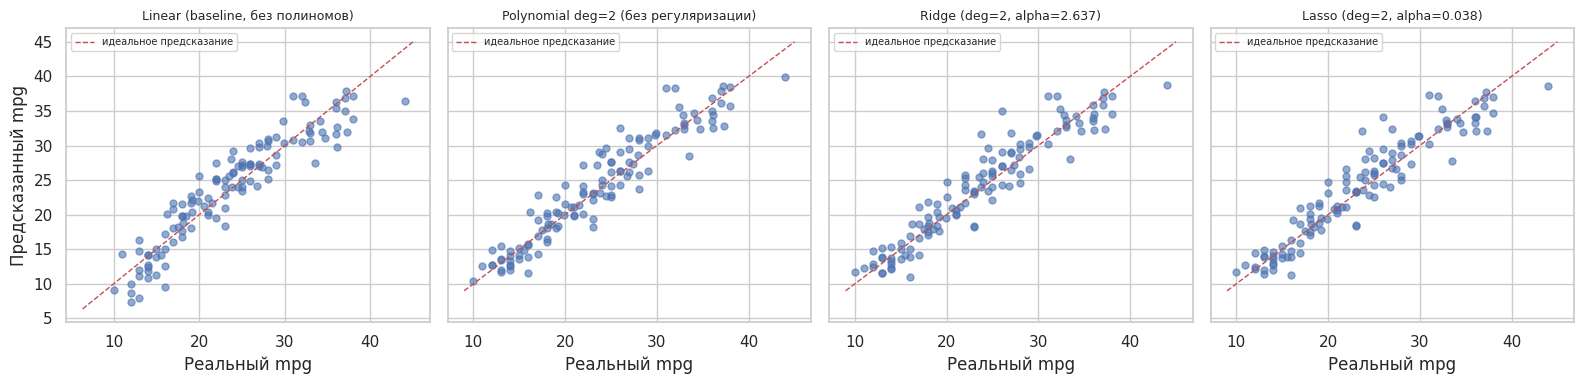

In [20]:
fig, axes = plt.subplots(1, len(test_predictions) + 1, figsize=(4 * (len(test_predictions) + 1), 4), sharey=True)

baseline_pred_test = final_models['Linear (baseline, без полиномов)'].predict(X_test)
all_preds = {'Linear (baseline, без полиномов)': baseline_pred_test, **test_predictions}

for ax, (name, pred) in zip(axes, all_preds.items()):
    ax.scatter(y_test, pred, alpha=0.6, s=25)
    lims = [min(y_test.min(), pred.min()) - 1, max(y_test.max(), pred.max()) + 1]
    ax.plot(lims, lims, 'r--', linewidth=1, label='идеальное предсказание')
    ax.set_xlabel('Реальный mpg')
    ax.set_title(name, fontsize=9)
    ax.legend(fontsize=7)

axes[0].set_ylabel('Предсказанный mpg')
plt.tight_layout()
plt.show()

### Ответы на контрольные вопросы

**1. Улучшила ли полиномиальная регрессия качество по сравнению с обычной линейной моделью?**
Да, заметно: test R² вырос с ≈0.86 (baseline) до ≈0.90 (полином степени 2), test MSE снизился
примерно с 7.9 до 6.0. Это подтверждает вывод из pairplot: связь `mpg` с `weight`/`horsepower`/`displacement`
действительно нелинейная, и квадратичные признаки помогают модели её уловить.

**2. Помогла ли регуляризация (Ridge) улучшить результат на тесте по сравнению с полиномиальной моделью без регуляризации? Если да, то почему?**
В данном случае — нет: на тестовой выборке Ridge с оптимальным по CV alpha показал MSE/R² чуть **хуже**,
чем обычная (нерегуляризованная) полиномиальная регрессия степени 2. Причина в том, что мы заранее подобрали
"безопасную" степень полинома (2) именно там, где переобучение ещё минимально (см. график в разделе 3) —
и модель без регуляризации уже неплохо обобщается. Регуляризация в первую очередь помогает бороться
с переобучением при **высоких** степенях (3+), где веса коэффициентов становятся огромными и нестабильными
(что хорошо видно по взрывному росту CV MSE на графике в разделе 3) — там Ridge/Lasso дали бы гораздо более
заметный выигрыш. При уже подобранной оптимальной сложности модели регуляризация добавляет смещение (bias),
не давая почти никакого выигрыша в дисперсии, и итоговое качество может слегка просесть.

**3. Какие признаки оказались самыми важными согласно коэффициентам Lasso?**
`model_year` (особенно поздние годы 79–82 — сильный положительный эффект на mpg), `weight`
(сильный отрицательный эффект), `horsepower` (отрицательный) и признак региона `origin_usa`
(отрицательный — американские машины в среднем менее экономичны при прочих равных). Lasso обнулил
примерно четверть коэффициентов (в основном полиномиальные взаимодействия и часть indicator-признаков
`model_year` с близким к нулю эффектом), продемонстрировав автоматический отбор признаков — то, чего
Ridge принципиально не делает (он лишь уменьшает коэффициенты, но не обнуляет их).

### Общий вывод

Лучший результат на тестовой выборке в этом эксперименте показала **полиномиальная регрессия степени 2
без регуляризации** (test R² ≈ 0.90, test MSE ≈ 6.0) — она заметно точнее базовой линейной модели и,
на этом конкретном разбиении train/test, слегка точнее регуляризованных вариантов. Регуляризация (Ridge/Lasso)
не столько улучшает пиковое качество при уже оптимально подобранной сложности модели, сколько служит
**страховкой** — если бы степень полинома была выбрана неудачно (слишком высокой), именно регуляризация
не позволила бы модели "развалиться" на тесте, как это произошло с нерегуляризованными полиномами степени 3+
на графике в разделе 3. Lasso дополнительно полезен как инструмент интерпретации и отбора признаков: он
явно указывает, что решающий вклад в предсказание расхода топлива вносят год выпуска, масса автомобиля и
мощность двигателя — что полностью согласуется с физическим смыслом задачи.